# ML Nhánh 1 : Giải mã Tuyến tính & Không gian

**Mô hình chủ lực:** `ml1_xdawn_lda` = xDAWN → Vectorizer → StandardScaler → Shrinkage LDA (`priors=[0.5, 0.5]`).
**Mô hình đối chứng:** `ml1_baseline_lr` = (giảm mẫu) → Vectorizer → StandardScaler → PCA(50) → LogisticRegression(`class_weight='balanced'`).

## Tuân thủ 7 chuẩn
| # | Chuẩn | Cách thực hiện trong notebook |
|---|---|---|
| 1 | 1 nguồn dữ liệu: **20.886 epoch, 39 subject** | Nạp `data/processed/X_clean.npy` + `metadata.csv`, kiểm tra cứng số epoch/subject/lớp (bật `EEG_STRICT=1`) |
| 2 | Dùng chung `splits/*.json` | Đọc `within_5fold.json` (195 fold), `loso.json` (39), `cross_5fold.json` (5) — hoặc file gộp `splits.json`; **không tự chia**; kiểm tra `trial_uid_sha256` |
| 3 | Zero leakage | Mỗi fold tạo pipeline mới, `.fit()` chỉ trên Train; có `assert` không trùng trial/subject |
| 4 | 6 metric: `bal_acc, roc_auc, pr_auc, f1_target, sensitivity, specificity` | Không dùng Accuracy; ngưỡng cố định 0.5 |
| 5 | Schema bàn giao | `results/handover_standard/{model}_{setting}_per_fold.csv` (8 cột) + `_preds.npz` (7 mảng), kèm bộ kiểm tra schema |
| 6 | Thời gian train & latency (ms/epoch, batch=1, CPU) | Ghi vào `results/metrics/` |
| 7 | Ablation ghép cặp | `cs5_clean` vs `cs5_no_ica` trên đúng các trial `kept_in_clean == True`, khớp theo `trial_uid`, Wilcoxon theo subject |

**4 setting:** `within`, `loso`, `cs5_clean`, `cs5_no_ica`.

> **Trước khi chạy:** `pytest -v tests/test_data_contract.py` phải PASS 5/5 (xác nhận đúng `trial_uid_sha256`).

In [ ]:
import os, sys, re, json, time, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from IPython.display import display
from scipy.stats import wilcoxon

from sklearn.metrics import (
    roc_auc_score, average_precision_score, balanced_accuracy_score,
    f1_score, recall_score, confusion_matrix, roc_curve, precision_recall_curve,
)

# --- Tìm thư mục gốc dự án (có src/models và data/processed) ---
def find_project_root() -> Path:
    env = os.getenv("EEG_ROOT")
    if env:
        return Path(env).resolve()
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "src" / "models").exists() and (cand / "data").exists():
            return cand
    return Path("../..").resolve()

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from scripts.training.spatial_linear import get_spatial_linear_models
try:   # dùng đúng hàm của repo nếu có để cùng giao thức với DL2
    from src.evaluation.metrics import find_optimal_threshold as _repo_find_threshold
    HAVE_REPO_THR = True
except Exception:   # chưa có repo/thiếu thư viện -> dùng bản dự phòng ở cell hàm lõi
    HAVE_REPO_THR = False
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
try:
    from sklearn.exceptions import ConvergenceWarning
    warnings.filterwarnings("ignore", category=ConvergenceWarning)
except ImportError:
    pass

# ------------------------------------------------------------------ Hằng số theo quy chuẩn V2.5
STRICT_CONTRACT = os.getenv("EEG_STRICT", "1") == "1"      # =1: kiểm tra cứng số liệu chuẩn của nhóm
SPEC = dict(n_epochs=20886, n_subjects=39, n_frequent=18036, n_target=2850, n_no_ica=22477,
            within_folds=195, loso_folds=39, cs5_folds=5)
SEED, THRESHOLD, VOLT_TO_UV = 42, 0.5, 1e6
EXPECTED_SHA = "7c5ce364eec45fc9c7d2ac3a2fc5d5723fd961b5953d9653cf403acda19eb524"   # trial_uid_sha256 chuẩn của nhóm
# Mỗi fold của splits có train / val / test rời nhau. Mặc định ML1 CHỈ fit trên train_idx (cùng dữ liệu fit với các nhánh DL,
# vốn dùng val để early stopping). Đặt True để fit trên train+val (nhiều dữ liệu hơn, nhưng KHÔNG cùng điều kiện với DL).
THRESHOLD_MODE = "fixed"
THR_CLIP = (0.05, 0.95)
USE_VAL_FOR_FIT = False
METRICS = ["bal_acc", "roc_auc", "pr_auc", "f1_target", "sensitivity", "specificity"]
SCHEMA_COLS = ["subject_id", "fold"] + METRICS
CS5_SUBJECT_LABEL = "ALL"   # nhãn subject_id cho dòng của cs5_* (đối chiếu file mẫu p300_atcnet_cs5_clean_per_fold.csv)

MODEL_MAIN, MODEL_BASE = "ml1_xdawn_lda", "ml1_baseline_lr"
RUN_BASELINE = True
BASELINE_SETTINGS = ["within", "cs5_clean", "cs5_no_ica"]   # thêm "loso" nếu đủ thời gian (39 fold PCA trên ~20k epoch)
BASELINE_DECIM = 5          # 250 Hz -> 50 Hz cho baseline (giảm RAM/thời gian ~5 lần)

data_dir = PROJECT_ROOT / "data" / "processed"
splits_dir = PROJECT_ROOT / "splits"
handover_dir = PROJECT_ROOT / "results" / "handover_standard"
metrics_dir = PROJECT_ROOT / "results" / "metrics"
figures_dir = PROJECT_ROOT / "results" / "figures"
for d in (handover_dir, metrics_dir, figures_dir):
    d.mkdir(parents=True, exist_ok=True)

print(f"PROJECT_ROOT = {PROJECT_ROOT}\nSTRICT_CONTRACT = {STRICT_CONTRACT}")

PROJECT_ROOT = C:\visualstudiocode\MiniProject-TTKHTK\EEG-mini-project
STRICT_CONTRACT = True


## 1. Nạp dữ liệu chuẩn (single source of truth)
`X_clean.npy` lưu ở **Volt (~1e-5)** → nhân `1e6` sang µV ngay khi nạp (tránh mất chính xác số học). Chỉ số dòng của `metadata.csv` khớp 1-1 với trục 0 của `X_clean.npy` (= `trial_idx` trong `_preds.npz`).

In [22]:
def pick_col(df, candidates, what):
    for c in candidates:
        if c in df.columns:
            return c
    raise KeyError(f"metadata thiếu cột {what}; đã thử {candidates}; hiện có: {list(df.columns)}")

meta = pd.read_csv(data_dir / "metadata.csv")
C_SUB = pick_col(meta, ["subject_id", "subject", "sub_id"], "subject")
C_LAB = pick_col(meta, ["label", "y"], "nhãn")
C_UID = pick_col(meta, ["trial_uid"], "trial_uid")

subject_ids = meta[C_SUB].astype(str).to_numpy()
y = meta[C_LAB].to_numpy().astype(np.int64)
trial_uid = meta[C_UID].astype(str).to_numpy()

print("Đang nạp X_clean.npy ...")
X = np.load(data_dir / "X_clean.npy")                  # float32, Volt
raw_med = float(np.median(np.abs(X[:: max(1, len(X) // 200)])))
X *= np.float32(VOLT_TO_UV)                            # -> µV (tại chỗ, không nhân đôi RAM)
print(f"|X| trung vị: {raw_med:.2e} V -> {raw_med * VOLT_TO_UV:.2f} µV")

assert X.shape[0] == len(meta), f"X ({X.shape[0]}) lệch metadata ({len(meta)})"
assert set(np.unique(y)) <= {0, 1}
assert np.isfinite(X[:: max(1, len(X) // 500)]).all(), "NaN/Inf trong X_clean"
assert len(set(trial_uid)) == len(trial_uid), "trial_uid bị trùng"
sha = hashlib.sha256("\n".join(trial_uid).encode()).hexdigest()    # cùng cách băm với splits.json
print("trial_uid_sha256:", sha)

unique_subs = np.unique(subject_ids)
n0, n1 = int((y == 0).sum()), int((y == 1).sum())
print("=" * 70)
print(f"X_clean:      {X.shape}  dtype={X.dtype}  ({X.nbytes / 1024**3:.2f} GB)")
print(f"Subjects:     {len(unique_subs)}")
print(f"Frequent (0): {n0}   Target (1): {n1}   Tỷ lệ {n0 / n1:.2f} : 1")
print("=" * 70)

if STRICT_CONTRACT:
    assert len(meta) == SPEC["n_epochs"], f"Sai nguồn dữ liệu: {len(meta)} epoch, chuẩn V2.5 là {SPEC['n_epochs']}. " \
        "Hãy dùng đúng 4 file tải từ Drive của Dương (không dùng X_clean tự sinh)."
    assert len(unique_subs) == SPEC["n_subjects"], f"{len(unique_subs)} subject, chuẩn là {SPEC['n_subjects']}"
    assert (n0, n1) == (SPEC["n_frequent"], SPEC["n_target"]), f"Lệch số lượng lớp: {(n0, n1)}"
    assert sha == EXPECTED_SHA, "trial_uid_sha256 KHÁC mã chuẩn của nhóm -> sai nguồn dữ liệu/metadata"
    print("✅ Khớp dữ liệu chuẩn V2.5 (20.886 epoch / 39 subject / 18.036 : 2.850 / đúng trial_uid_sha256).")
else:
    print("⚠️ EEG_STRICT=0: bỏ qua kiểm tra số liệu chuẩn (chỉ dùng để thử nghiệm).")

Đang nạp X_clean.npy ...
|X| trung vị: 4.23e-06 V -> 4.23 µV
trial_uid_sha256: 7c5ce364eec45fc9c7d2ac3a2fc5d5723fd961b5953d9653cf403acda19eb524
X_clean:      (20886, 127, 251)  dtype=float32  (2.48 GB)
Subjects:     39
Frequent (0): 18036   Target (1): 2850   Tỷ lệ 6.33 : 1
✅ Khớp dữ liệu chuẩn V2.5 (20.886 epoch / 39 subject / 18.036 : 2.850 / đúng trial_uid_sha256).


## 2. Nạp splits dùng chung (không tự chia fold)
Nguồn: `splits/within_5fold.json`, `splits/cross_5fold.json`, `splits/loso.json`; nếu chưa có thì lấy từ file gộp `data/processed/splits.json`
(các khóa `within_subject`, `cross_subject_5fold`, `cross_subject_loso`). Mỗi fold có **`train_idx` / `val_idx` / `test_idx` rời nhau**; chỉ số là **số dòng** của `metadata.csv` / trục 0 của `X_clean.npy`.

- `fold`: lấy từ JSON (within 0..4 trong từng subject; loso 0..38; cs5 0..4).
- **Fit trên `train_idx`** (xem `USE_VAL_FOR_FIT`); `val_idx` không dùng để fit/tuning ở ML1 (không có siêu tham số cần chọn), nhằm giữ cùng dữ liệu huấn luyện với nhánh DL.
- Kiểm tra: Train/Val/Test rời nhau, mỗi trial ở Test đúng 1 lần, LOSO đúng 1 subject/Test, cross không chung subject giữa Train/Val/Test, và `trial_uid_sha256` của file splits trùng với `metadata.csv`.

In [ ]:
TRAIN_KEYS = ["train_idx", "train_indices", "train"]
VAL_KEYS = ["val_idx", "val_indices", "val"]
TEST_KEYS = ["test_idx", "test_indices", "test"]
TEST_SUBJ_KEYS = ["test_subjects", "test_subject", "subject_id", "subject", "held_out_subject"]
SPLIT_FILES = {"within": "within_5fold.json", "cs5": "cross_5fold.json", "loso": "loso.json"}
COMBINED_KEYS = {"within": "within_subject", "cs5": "cross_subject_5fold", "loso": "cross_subject_loso"}

def _first(d, keys):
    for k in keys:
        if k in d:
            return d[k]
    return None

def _flatten(obj, path=()):
    # Duyệt đệ quy, trả về mọi dict có cả khóa train và test (kèm đường dẫn khóa, vd ('sub-01', '0')).
    if isinstance(obj, dict):
        if _first(obj, TEST_KEYS) is not None and _first(obj, TRAIN_KEYS) is not None:
            yield obj, path
        else:
            for k, v in obj.items():
                yield from _flatten(v, path + (str(k),))
    elif isinstance(obj, list):
        for i, v in enumerate(obj):
            yield from _flatten(v, path + (str(i),))

uid_to_idx = {u: i for i, u in enumerate(trial_uid)}

def _to_idx(arr):
    a = np.asarray(arr)
    if a.size == 0:
        return np.array([], dtype=np.int64)
    if a.dtype.kind in "US" or a.dtype == object:
        return np.array([uid_to_idx[str(u)] for u in a], dtype=np.int64)    # cho phép chỉ số bằng trial_uid
    return a.astype(np.int64)

def _read_split_obj(kind):
    f = splits_dir / SPLIT_FILES[kind]
    if f.exists():
        obj, src = json.load(open(f, encoding="utf-8")), f"splits/{f.name}"
    else:
        comb = next((p for p in (data_dir / "splits.json", splits_dir / "splits.json", PROJECT_ROOT / "splits.json") if p.exists()), None)
        if comb is None:
            raise FileNotFoundError(f"Không thấy {f} và cũng không có splits.json gộp (data/processed/ hoặc splits/).")
        full = json.load(open(comb, encoding="utf-8"))
        obj, src = full[COMBINED_KEYS[kind]], f"{comb.name}['{COMBINED_KEYS[kind]}']"
        obj = {"trial_uid_sha256": full.get("trial_uid_sha256"), "data": obj}
    sha_in_file = obj.get("trial_uid_sha256") if isinstance(obj, dict) else None
    if sha_in_file is not None:
        assert sha_in_file == sha, f"{src}: trial_uid_sha256 của splits KHÁC metadata.csv -> splits và dữ liệu không cùng nguồn"
    return obj, src

def load_splits(kind):
    obj, src = _read_split_obj(kind)
    leaves = list(_flatten(obj))
    if not leaves:
        raise ValueError(f"Không nhận ra cấu trúc {src}; các khóa cấp 1: {list(obj.keys())[:10] if isinstance(obj, dict) else type(obj)}")
    folds, counter = [], {}
    for i, (r, path) in enumerate(leaves):
        tr, va, te = _to_idx(_first(r, TRAIN_KEYS)), _to_idx(_first(r, VAL_KEYS) or []), _to_idx(_first(r, TEST_KEYS))
        subj = _first(r, TEST_SUBJ_KEYS)
        if isinstance(subj, (list, tuple)):
            subj = subj[0] if len(subj) == 1 else ",".join(map(str, subj))
        if subj is None:
            subj = next((p for p in path if re.fullmatch(r"sub-\d+", p)), None)
        if subj is None:
            u = np.unique(subject_ids[te]); subj = str(u[0]) if len(u) == 1 else CS5_SUBJECT_LABEL
        subj = str(subj)
        fold = r.get("fold")
        if not isinstance(fold, (int, np.integer)):
            if kind == "within":
                fold = counter.get(subj, 0); counter[subj] = fold + 1
            else:
                fold = i
        fit = np.concatenate([tr, va]) if USE_VAL_FOR_FIT else tr
        folds.append(dict(subject_id=subj, fold=int(fold), train_idx=tr, val_idx=va, test_idx=te, fit_idx=fit))
    print(f"  nguồn {kind:6s}: {src}")
    return folds

def check_splits(folds, kind):
    n = len(y)
    cnt = np.zeros(n, int)
    for f in folds:
        tr, va, te = f["train_idx"], f["val_idx"], f["test_idx"]
        for a in (tr, va, te):
            assert len(a) == 0 or (a.min() >= 0 and a.max() < n), "chỉ số ngoài phạm vi"
        assert not set(tr) & set(te), f"[{kind}] fold {f['fold']}: Train và Test trùng trial!"
        assert not set(va) & set(te) and not set(va) & set(tr), f"[{kind}] fold {f['fold']}: Val trùng Train/Test!"
        cnt[te] += 1
        if kind in ("loso", "cs5"):
            s_tr, s_va, s_te = (set(subject_ids[a]) for a in (tr, va, te))
            assert not (s_tr & s_te) and not (s_va & s_te) and not (s_tr & s_va), f"[{kind}] fold {f['fold']}: rò rỉ subject"
        if kind == "loso":
            assert len(set(subject_ids[te])) == 1, "LOSO: Test phải đúng 1 subject"
        if kind == "within":
            assert len(set(subject_ids[np.concatenate([tr, va, te])])) == 1, "within: mỗi fold chỉ 1 subject"
    assert (cnt == 1).all(), f"[{kind}] mỗi trial phải nằm ở Test đúng 1 lần (min={cnt.min()}, max={cnt.max()})"
    return True

print("Nạp splits:")
SPLITS = {k: load_splits(k) for k in ("within", "loso", "cs5")}
exp = {"within": len(unique_subs) * 5, "loso": len(unique_subs), "cs5": 5}
if STRICT_CONTRACT:
    exp = {"within": SPEC["within_folds"], "loso": SPEC["loso_folds"], "cs5": SPEC["cs5_folds"]}
for k, folds in SPLITS.items():
    check_splits(folds, k)
    assert len(folds) == exp[k], f"{k}: {len(folds)} fold, kỳ vọng {exp[k]}"
    print(f"✅ {k:7s}: {len(folds):3d} fold | fit≈{np.mean([len(f['fit_idx']) for f in folds]):.0f} "
          f"| val≈{np.mean([len(f['val_idx']) for f in folds]):.0f} | test≈{np.mean([len(f['test_idx']) for f in folds]):.0f}"
          f"{'  (fit gồm train+val)' if USE_VAL_FOR_FIT else '  (fit = train_idx)'}")

Nạp splits:
  nguồn within: splits/within_5fold.json
  nguồn loso  : splits/loso.json
  nguồn cs5   : splits/cross_5fold.json
✅ within : 195 fold | fit≈342 | val≈86 | test≈107  (fit = train_idx)
✅ loso   :  39 fold | fit≈18196 | val≈2155 | test≈536  (fit = train_idx)
✅ cs5    :   5 fold | fit≈13487 | val≈3222 | test≈4177  (fit = train_idx)


## 3. Hàm lõi: huấn luyện theo fold, 6 metric, xuất schema, kiểm tra schema

In [ ]:
def compute_metrics(y_true, y_prob, thr=THRESHOLD, y_pred=None):
    """6 metric chuẩn V2.5 (không dùng Accuracy). y_pred cho sẵn, hoặc suy ra từ ngưỡng thr."""
    if y_pred is None:
        y_pred = (y_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "bal_acc": balanced_accuracy_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "pr_auc": average_precision_score(y_true, y_prob),
        "f1_target": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "sensitivity": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "specificity": tn / (tn + fp) if (tn + fp) else 0.0,
    }

def _fallback_threshold(y_true, y_prob):
    """Dự phòng khi không import được hàm của repo: lưới 0.01 trong THR_CLIP, tối đa Balanced Accuracy, hòa thì chọn gần 0.5."""
    y_true = np.asarray(y_true)
    if len(np.unique(y_true)) < 2:
        return 0.5
    best_s, best_t = -1.0, 0.5
    for t in np.round(np.arange(THR_CLIP[0], THR_CLIP[1] + 1e-9, 0.01), 2):
        pr = y_prob >= t
        sens = (pr & (y_true == 1)).sum() / max((y_true == 1).sum(), 1)
        spec = (~pr & (y_true == 0)).sum() / max((y_true == 0).sum(), 1)
        sc = 0.5 * (sens + spec)
        if sc > best_s + 1e-12 or (abs(sc - best_s) <= 1e-12 and abs(t - 0.5) < abs(best_t - 0.5)):
            best_s, best_t = sc, float(t)
    return best_t

def choose_threshold(y_val, p_val):
    if THRESHOLD_MODE == "fixed" or len(y_val) == 0:
        return THRESHOLD
    assert not USE_VAL_FOR_FIT, "THRESHOLD_MODE='val' yêu cầu USE_VAL_FOR_FIT=False (val chỉ để chọn ngưỡng)"
    if HAVE_REPO_THR:
        thr = _repo_find_threshold(y_val, p_val, metric="balanced_accuracy")
    else:
        thr = _fallback_threshold(y_val, p_val)
    return float(np.clip(thr, *THR_CLIP))

THRESHOLDS = []   # ngưỡng đã dùng theo từng fold (lưu sang results/metrics/, không nằm trong handover)

def make_model(model_key):
    if model_key == MODEL_MAIN:
        return get_spatial_linear_models(n_components=4, random_state=SEED)["xDAWN_ShrinkageLDA"]
    if model_key == MODEL_BASE:
        return get_spatial_linear_models(n_components=4, random_state=SEED,
                                         baseline_decim=BASELINE_DECIM)["Baseline_Vectorizer_LR"]
    raise KeyError(model_key)

TIMING = []   # thời gian huấn luyện theo (model, setting)

def run_setting(model_key, setting, X_set, folds):
    """Chạy toàn bộ fold của 1 setting. Mỗi fold: pipeline MỚI, fit CHỈ trên Train. Trả (per_fold_df, preds)."""
    n = len(y)
    y_prob = np.full(n, np.nan)
    thr_arr = np.full(n, np.nan)
    fold_of = np.full(n, -1, dtype=np.int64)
    rows, fit_s, pred_s = [], [], []
    for f in tqdm(folds, desc=f"{model_key} | {setting}"):
        tr, te = f["fit_idx"], f["test_idx"]      # fit_idx = train_idx (hoặc train+val nếu USE_VAL_FOR_FIT)
        model = make_model(model_key)
        t0 = time.perf_counter(); model.fit(X_set[tr], y[tr]); fit_s.append(time.perf_counter() - t0)
        t0 = time.perf_counter(); prob = model.predict_proba(X_set[te])[:, 1]; pred_s.append(time.perf_counter() - t0)
        vi = f["val_idx"]
        thr = choose_threshold(y[vi], model.predict_proba(X_set[vi])[:, 1]) if THRESHOLD_MODE == "val" else THRESHOLD
        y_prob[te], fold_of[te], thr_arr[te] = prob, f["fold"], thr
        THRESHOLDS.append({"model": model_key, "setting": setting, "subject_id": f["subject_id"], "fold": f["fold"], "threshold": thr})
        row = {"subject_id": f["subject_id"], "fold": f["fold"]}
        row.update(compute_metrics(y[te], prob, thr=thr))
        rows.append(row)
        del model
    assert not np.isnan(y_prob).any() and (fold_of >= 0).all(), "Còn trial chưa được dự đoán"
    per_fold = pd.DataFrame(rows)[SCHEMA_COLS]
    preds = dict(
        subject_id=np.asarray(subject_ids, dtype=str),    # subject thật của từng trial (khớp metadata)
        fold=fold_of,
        trial_idx=np.arange(n, dtype=np.int64),
        trial_uid=np.asarray(trial_uid, dtype=str),
        y_true=y.astype(np.int64),
        y_prob=y_prob.astype(np.float64),
        y_pred=(y_prob >= thr_arr).astype(np.int64),
    )
    TIMING.append(dict(model=model_key, setting=setting, n_folds=len(folds),
                       train_total_s=sum(fit_s), train_mean_s_per_fold=float(np.mean(fit_s)),
                       predict_total_s=sum(pred_s), n_test_epochs=n))
    return per_fold, preds

def export_handover(model_key, setting, per_fold, preds):
    p_csv = handover_dir / f"{model_key}_{setting}_per_fold.csv"
    p_npz = handover_dir / f"{model_key}_{setting}_preds.npz"
    per_fold.to_csv(p_csv, index=False)
    np.savez_compressed(p_npz, **preds)
    return p_csv, p_npz

def validate_handover(model_key, setting):
    """Kiểm tra schema giống smoke_test_results.py (đọc lại từ đĩa, allow_pickle=False)."""
    p_csv = handover_dir / f"{model_key}_{setting}_per_fold.csv"
    p_npz = handover_dir / f"{model_key}_{setting}_preds.npz"
    df = pd.read_csv(p_csv)
    assert list(df.columns) == SCHEMA_COLS, f"cột sai: {list(df.columns)}"
    n_exp = {"within": SPEC["within_folds"] if STRICT_CONTRACT else len(SPLITS["within"]),
             "loso": SPEC["loso_folds"] if STRICT_CONTRACT else len(SPLITS["loso"])}.get(
                 setting, SPEC["cs5_folds"] if STRICT_CONTRACT else len(SPLITS["cs5"]))
    assert len(df) == n_exp, f"{len(df)} dòng, kỳ vọng {n_exp}"
    assert np.isfinite(df[METRICS].to_numpy()).all(), "có NaN/Inf"
    assert ((df[METRICS] >= 0) & (df[METRICS] <= 1)).all().all(), "metric ngoài [0, 1]"
    if setting == "loso":
        assert sorted(df["fold"]) == list(range(len(df))), "loso: fold phải là 0..N-1"
    z = np.load(p_npz, allow_pickle=False)
    need = {"subject_id", "fold", "trial_idx", "trial_uid", "y_true", "y_prob", "y_pred"}
    assert set(z.files) == need, f"mảng sai: {z.files}"
    n = len(meta)
    assert all(len(z[k]) == n for k in need), "độ dài mảng khác số epoch"
    assert z["subject_id"].dtype.kind == "U" and z["trial_uid"].dtype.kind == "U", "chuỗi phải là <U"
    assert np.array_equal(z["trial_idx"], np.arange(n))
    assert np.array_equal(z["trial_uid"], trial_uid.astype(str))
    assert np.array_equal(z["y_true"], meta[C_LAB].to_numpy()), "y_true không khớp metadata['label']"
    assert z["y_prob"].min() >= 0 and z["y_prob"].max() <= 1
    assert set(np.unique(z["y_pred"])) <= {0, 1}
    # y_pred phải do ĐÚNG 1 ngưỡng cho mỗi (subject, fold) tạo ra, và ngưỡng đó nằm trong [0.05, 0.95]
    key = np.char.add(np.char.add(z["subject_id"], "|"), z["fold"].astype(str))
    for k in np.unique(key):
        m = key == k
        p, yp = z["y_prob"][m], z["y_pred"][m]
        lo = p[yp == 0].max() if (yp == 0).any() else 0.0
        hi = p[yp == 1].min() if (yp == 1).any() else 1.0
        assert lo < hi, f"y_pred không nhất quán với một ngưỡng duy nhất tại {k}"
    return True

def run_and_export(model_key, setting, X_set, folds):
    per_fold, preds = run_setting(model_key, setting, X_set, folds)
    p_csv, p_npz = export_handover(model_key, setting, per_fold, preds)
    validate_handover(model_key, setting)
    print(f"✅ {model_key} | {setting}: {len(per_fold)} dòng -> {p_csv.name}, {p_npz.name}  (schema OK)")
    return per_fold, preds

RESULTS = {}   # (model, setting) -> (per_fold, preds)

## 4. Chạy 4 setting cho `ml1_xdawn_lda`

In [25]:
# --- within (195 fold) ---
RESULTS[(MODEL_MAIN, "within")] = run_and_export(MODEL_MAIN, "within", X, SPLITS["within"])

ml1_xdawn_lda | within:   0%|          | 0/195 [00:00<?, ?it/s]

✅ ml1_xdawn_lda | within: 195 dòng -> ml1_xdawn_lda_within_per_fold.csv, ml1_xdawn_lda_within_preds.npz  (schema OK)


In [26]:
# --- loso (39 fold; kết quả CHÍNH cho RQ1/RQ2) ---
RESULTS[(MODEL_MAIN, "loso")] = run_and_export(MODEL_MAIN, "loso", X, SPLITS["loso"])

ml1_xdawn_lda | loso:   0%|          | 0/39 [00:00<?, ?it/s]

✅ ml1_xdawn_lda | loso: 39 dòng -> ml1_xdawn_lda_loso_per_fold.csv, ml1_xdawn_lda_loso_preds.npz  (schema OK)


In [27]:
# --- cs5_clean (5 fold) ---
RESULTS[(MODEL_MAIN, "cs5_clean")] = run_and_export(MODEL_MAIN, "cs5_clean", X, SPLITS["cs5"])

ml1_xdawn_lda | cs5_clean:   0%|          | 0/5 [00:00<?, ?it/s]

✅ ml1_xdawn_lda | cs5_clean: 5 dòng -> ml1_xdawn_lda_cs5_clean_per_fold.csv, ml1_xdawn_lda_cs5_clean_preds.npz  (schema OK)


### `cs5_no_ica` — ablation ghép cặp
Lấy `X_no_ica_no_reject.npy` rồi chọn **đúng** các dòng `kept_in_clean == True`, **sắp xếp theo `trial_uid` của `metadata.csv`** để dòng *i* của hai bộ là cùng một trial. Nhờ vậy cùng `splits/cross_5fold.json`, cùng nhãn, cùng subject; chênh lệch chỉ do ICA.

In [ ]:
meta_no = pd.read_csv(data_dir / "metadata_no_ica.csv")
assert "trial_uid" in meta_no.columns and "kept_in_clean" in meta_no.columns, f"cột: {list(meta_no.columns)}"
if STRICT_CONTRACT:
    assert len(meta_no) == SPEC["n_no_ica"], f"metadata_no_ica có {len(meta_no)} dòng, chuẩn {SPEC['n_no_ica']}"

kept = meta_no["kept_in_clean"].astype(bool).to_numpy()
assert kept.sum() == len(meta), f"kept_in_clean=True: {kept.sum()} ≠ {len(meta)}"
pos_no = {str(u): i for i, u in enumerate(meta_no["trial_uid"].astype(str))}
rows_no = np.array([pos_no[u] for u in trial_uid])                 # KeyError nếu thiếu trial
assert kept[rows_no].all(), "Có trial của X_clean không được đánh dấu kept_in_clean"
# Kiểm tra chéo: cùng trial_uid thì phải cùng nhãn và cùng subject ở hai file metadata
_c_lab = pick_col(meta_no, ["label", "y"], "nhãn (metadata_no_ica)")
_c_sub = pick_col(meta_no, ["subject_id", "subject", "sub_id"], "subject (metadata_no_ica)")
assert (meta_no[_c_lab].to_numpy()[rows_no] == y).all(), "Nhãn của metadata_no_ica KHÔNG khớp metadata.csv"
assert (meta_no[_c_sub].astype(str).to_numpy()[rows_no] == subject_ids).all(), "subject của metadata_no_ica KHÔNG khớp metadata.csv"
if STRICT_CONTRACT:
    assert (int((meta_no[_c_lab] == 0).sum()), int((meta_no[_c_lab] == 1).sum())) == (19475, 3002), "Lệch số lớp của bộ no_ica (chuẩn 19.475/3.002)"

X_no_all = np.load(data_dir / "X_no_ica_no_reject.npy", mmap_mode="r")
assert X_no_all.shape[0] == len(meta_no)
X_no = np.asarray(X_no_all[rows_no], dtype=np.float32)              # đã đúng thứ tự metadata.csv
X_no *= np.float32(VOLT_TO_UV)
del X_no_all
print(f"X_no_ica (ghép cặp): {X_no.shape} | dòng i khớp trial_uid với X_clean: ✅")

RESULTS[(MODEL_MAIN, "cs5_no_ica")] = run_and_export(MODEL_MAIN, "cs5_no_ica", X_no, SPLITS["cs5"])

X_no_ica (ghép cặp): (20886, 127, 251) | dòng i khớp trial_uid với X_clean: ✅


ml1_xdawn_lda | cs5_no_ica:   0%|          | 0/5 [00:00<?, ?it/s]

✅ ml1_xdawn_lda | cs5_no_ica: 5 dòng -> ml1_xdawn_lda_cs5_no_ica_per_fold.csv, ml1_xdawn_lda_cs5_no_ica_preds.npz  (schema OK)


## 5. Mô hình đối chứng `ml1_baseline_lr` (tùy chọn, dùng cho luận điểm "xDAWN vượt baseline")
Chạy trên `BASELINE_SETTINGS` (mặc định không gồm `loso` để tiết kiệm thời gian; thêm vào nếu muốn đủ 4 setting).

In [ ]:
if RUN_BASELINE:
    for setting in BASELINE_SETTINGS:
        data_for = X_no if setting == "cs5_no_ica" else X
        folds = SPLITS["within"] if setting == "within" else SPLITS["loso"] if setting == "loso" else SPLITS["cs5"]
        RESULTS[(MODEL_BASE, setting)] = run_and_export(MODEL_BASE, setting, data_for, folds)
else:
    print("RUN_BASELINE=False: bỏ qua baseline.")

ml1_baseline_lr | within:   0%|          | 0/195 [00:00<?, ?it/s]

✅ ml1_baseline_lr | within: 195 dòng -> ml1_baseline_lr_within_per_fold.csv, ml1_baseline_lr_within_preds.npz  (schema OK)


ml1_baseline_lr | cs5_clean:   0%|          | 0/5 [00:00<?, ?it/s]

✅ ml1_baseline_lr | cs5_clean: 5 dòng -> ml1_baseline_lr_cs5_clean_per_fold.csv, ml1_baseline_lr_cs5_clean_preds.npz  (schema OK)


ml1_baseline_lr | cs5_no_ica:   0%|          | 0/5 [00:00<?, ?it/s]

✅ ml1_baseline_lr | cs5_no_ica: 5 dòng -> ml1_baseline_lr_cs5_no_ica_per_fold.csv, ml1_baseline_lr_cs5_no_ica_preds.npz  (schema OK)


## 6. Thời gian huấn luyện & Inference latency (batch_size = 1, CPU)
Latency đo trên pipeline đã fit ở fold 0 của `cross_5fold`: gọi `predict_proba` cho **từng epoch riêng lẻ** (gồm xDAWN + Vectorizer + Scaler + LDA), có khởi động (warm-up) và lặp nhiều epoch. Kết quả lưu ở `results/metrics/` (không đặt trong `handover_standard/` để không lẫn với file schema).

In [ ]:
def benchmark_latency(model_key, X_set, fold, n_warmup=20, n_eval=500):
    model = make_model(model_key)
    model.fit(X_set[fold["fit_idx"]], y[fold["fit_idx"]])
    te = fold["test_idx"][:n_eval + n_warmup]
    for i in te[:n_warmup]:
        model.predict_proba(X_set[i:i + 1])
    lat = []
    for i in te[n_warmup:]:
        xb = X_set[i:i + 1]
        t0 = time.perf_counter(); model.predict_proba(xb); lat.append((time.perf_counter() - t0) * 1000)
    lat = np.asarray(lat)
    return dict(model=model_key, device="CPU", batch_size=1, n_epochs_timed=len(lat),
                latency_ms_mean=lat.mean(), latency_ms_std=lat.std(), latency_ms_median=np.median(lat),
                latency_ms_p95=np.percentile(lat, 95))

LATENCY = [benchmark_latency(MODEL_MAIN, X, SPLITS["cs5"][0])]
if RUN_BASELINE:
    LATENCY.append(benchmark_latency(MODEL_BASE, X, SPLITS["cs5"][0]))

timing_df, latency_df = pd.DataFrame(TIMING), pd.DataFrame(LATENCY)
timing_df = timing_df.drop_duplicates(["model", "setting"], keep="last")      # chạy lại cell nào thì lấy dòng mới nhất
timing_df.to_csv(metrics_dir / "ml1_train_time.csv", index=False)
pd.DataFrame(THRESHOLDS).drop_duplicates(["model", "setting", "subject_id", "fold"], keep="last").to_csv(metrics_dir / "ml1_thresholds.csv", index=False)
latency_df.to_csv(metrics_dir / "ml1_inference_latency.csv", index=False)
print("Thời gian huấn luyện:"); display(timing_df.round(2))
print("Inference latency (ms/epoch, batch=1, CPU):"); display(latency_df.round(3))
cfg_log = {"model_main": "xDAWN(n_components=4)->Vectorizer->StandardScaler->LDA(lsqr, shrinkage=auto, priors=[0.5,0.5])",
           "model_baseline": f"decim={BASELINE_DECIM}->Vectorizer->StandardScaler->PCA(50)->LR(C=0.1, class_weight=balanced)",
           "threshold_mode": THRESHOLD_MODE, "threshold_fixed": THRESHOLD, "threshold_clip": THR_CLIP,
           "threshold_function": "repo find_optimal_threshold" if (THRESHOLD_MODE == "val" and HAVE_REPO_THR) else ("fallback grid" if THRESHOLD_MODE == "val" else "n/a"),
           "seed": SEED, "fit_on": "train+val" if USE_VAL_FOR_FIT else "train_idx only", "class_imbalance": f"{n0 / n1:.2f}:1",
           "imbalance_handling": "LDA priors=[0.5,0.5]; LR class_weight=balanced"}
(metrics_dir / "ml1_config.json").write_text(json.dumps(cfg_log, indent=2, ensure_ascii=False), encoding="utf-8")

Thời gian huấn luyện:


,model,setting,n_folds,train_total_s,train_mean_s_per_fold,predict_total_s,n_test_epochs
0,ml1_xdawn_lda,within,195,597.83,3.07,4.97,20886
1,ml1_xdawn_lda,loso,39,1305.65,33.48,11.76,20886
2,ml1_xdawn_lda,cs5_clean,5,98.68,19.74,11.03,20886
3,ml1_xdawn_lda,cs5_no_ica,5,99.48,19.90,8.05,20886
4,ml1_baseline_lr,within,195,56.18,0.29,4.25,20886
5,ml1_baseline_lr,cs5_clean,5,63.13,12.63,10.86,20886
6,ml1_baseline_lr,cs5_no_ica,5,57.68,11.54,7.93,20886


Inference latency (ms/epoch, batch=1, CPU):


,model,device,batch_size,n_epochs_timed,latency_ms_mean,latency_ms_std,latency_ms_median,latency_ms_p95
0,ml1_xdawn_lda,CPU,1,500,0.783,0.153,0.748,1.117
1,ml1_baseline_lr,CPU,1,500,0.942,0.141,0.925,1.181


387

## 7. Tổng hợp kết quả (Mean ± SD)
- `within`, `loso`: trung bình các fold **theo từng subject**, rồi Mean ± SD **giữa 39 subject**.
- `cs5_*`: Mean ± SD giữa 5 fold.

In [ ]:
def summarize(per_fold, setting):
    d = per_fold.groupby("subject_id")[METRICS].mean() if setting in ("within", "loso") else per_fold[METRICS]
    return {"N_units": len(d), **{m: f"{d[m].mean():.4f} ± {d[m].std():.4f}" for m in METRICS},
            **{f"{m}_mean": d[m].mean() for m in METRICS}, **{f"{m}_std": d[m].std() for m in METRICS}}

rows = []
for (model, setting), (pf, _) in RESULTS.items():
    rows.append({"Model": model, "Setting": setting, **summarize(pf, setting)})
summary_df = pd.DataFrame(rows)
summary_df.to_csv(metrics_dir / "ml1_summary.csv", index=False)
display(summary_df[["Model", "Setting", "N_units"] + METRICS])

,Model,Setting,N_units,bal_acc,roc_auc,pr_auc,f1_target,sensitivity,specificity
0,ml1_xdawn_lda,within,39,0.8654 ± 0.0991,0.9571 ± 0.0715,0.8706 ± 0.1531,0.7951 ± 0.1763,0.7460 ± 0.1898,0.9848 ± 0.0122
1,ml1_xdawn_lda,loso,39,0.8610 ± 0.0790,0.9374 ± 0.0556,0.7874 ± 0.1525,0.6836 ± 0.1173,0.8117 ± 0.1587,0.9103 ± 0.0479
2,ml1_xdawn_lda,cs5_clean,5,0.8478 ± 0.0310,0.9249 ± 0.0281,0.7369 ± 0.0891,0.6666 ± 0.0756,0.7893 ± 0.0373,0.9062 ± 0.0342
3,ml1_xdawn_lda,cs5_no_ica,5,0.8334 ± 0.0270,0.9128 ± 0.0253,0.6894 ± 0.1183,0.6307 ± 0.0521,0.7766 ± 0.0492,0.8903 ± 0.0290
4,ml1_baseline_lr,within,39,0.8379 ± 0.0787,0.9279 ± 0.0698,0.7748 ± 0.1644,0.7073 ± 0.1483,0.7308 ± 0.1270,0.9451 ± 0.0375
5,ml1_baseline_lr,cs5_clean,5,0.8370 ± 0.0345,0.9078 ± 0.0276,0.6817 ± 0.0701,0.5970 ± 0.0624,0.8236 ± 0.0436,0.8504 ± 0.0293
6,ml1_baseline_lr,cs5_no_ica,5,0.8060 ± 0.0268,0.8869 ± 0.0224,0.5923 ± 0.0792,0.5427 ± 0.0489,0.7917 ± 0.0347,0.8204 ± 0.0315


## 8. RQ1 — Ablation ICA ghép cặp (`cs5_clean` vs `cs5_no_ica`)
Hai bộ cùng trial, cùng fold. Tính metric **theo từng subject** từ dự đoán out-of-fold, rồi kiểm định Wilcoxon signed-rank ghép cặp trên 39 subject; thêm chênh lệch theo 5 fold.

In [ ]:
def per_subject_metrics(preds):
    out = {}
    for s in np.unique(preds["subject_id"]):
        m = preds["subject_id"] == s
        out[s] = compute_metrics(preds["y_true"][m], preds["y_prob"][m], y_pred=preds["y_pred"][m])
    return pd.DataFrame(out).T[METRICS]

pc, pn = RESULTS[(MODEL_MAIN, "cs5_clean")], RESULTS[(MODEL_MAIN, "cs5_no_ica")]
assert np.array_equal(pc[1]["y_true"], pn[1]["y_true"]) and np.array_equal(pc[1]["trial_uid"], pn[1]["trial_uid"])
assert np.array_equal(pc[1]["fold"], pn[1]["fold"]), "hai bộ phải dùng cùng fold"

sc, sn = per_subject_metrics(pc[1]), per_subject_metrics(pn[1])
fc, fn_ = pc[0].set_index("fold")[METRICS], pn[0].set_index("fold")[METRICS]
abl_rows = []
for m in METRICS:
    d = (sc[m] - sn[m]).to_numpy()
    try:
        p = wilcoxon(d).pvalue if np.any(d != 0) else np.nan
    except ValueError:
        p = np.nan
    abl_rows.append({
        "Metric": m,
        "No-ICA (mean±SD, subject)": f"{sn[m].mean():.4f} ± {sn[m].std():.4f}",
        "Clean (mean±SD, subject)": f"{sc[m].mean():.4f} ± {sc[m].std():.4f}",
        "Delta (subject)": f"{d.mean():+.4f}",
        "Subjects cải thiện": f"{int((d > 0).sum())}/{len(d)}",
        "Wilcoxon p": p,
        "Delta (5-fold)": f"{(fc[m] - fn_[m]).mean():+.4f}",
        "Folds cải thiện": f"{int(((fc[m] - fn_[m]) > 0).sum())}/{len(fc)}",
    })
ablation_df = pd.DataFrame(abl_rows)
ablation_df.to_csv(metrics_dir / "ml1_ablation_ica_cs5.csv", index=False)
display(ablation_df)

,Metric,"No-ICA (mean±SD, subject)","Clean (mean±SD, subject)",Delta (subject),Subjects cải thiện,Wilcoxon p,Delta (5-fold),Folds cải thiện
0,bal_acc,0.8321 ± 0.0722,0.8462 ± 0.0750,+0.0141,26/39,0.027825,+0.0143,4/5
1,roc_auc,0.9213 ± 0.0600,0.9288 ± 0.0567,+0.0075,26/39,0.117209,+0.0121,4/5
2,pr_auc,0.7352 ± 0.1595,0.7603 ± 0.1530,+0.0252,20/39,0.214257,+0.0475,3/5
3,f1_target,0.6307 ± 0.1087,0.6623 ± 0.1165,+0.0316,24/39,0.018213,+0.0359,4/5
4,sensitivity,0.7777 ± 0.1562,0.7896 ± 0.1488,+0.0119,22/39,0.235549,+0.0127,3/5
5,specificity,0.8865 ± 0.0698,0.9028 ± 0.0583,+0.0162,22/39,0.154154,+0.0159,4/5


## 9. Hình minh họa

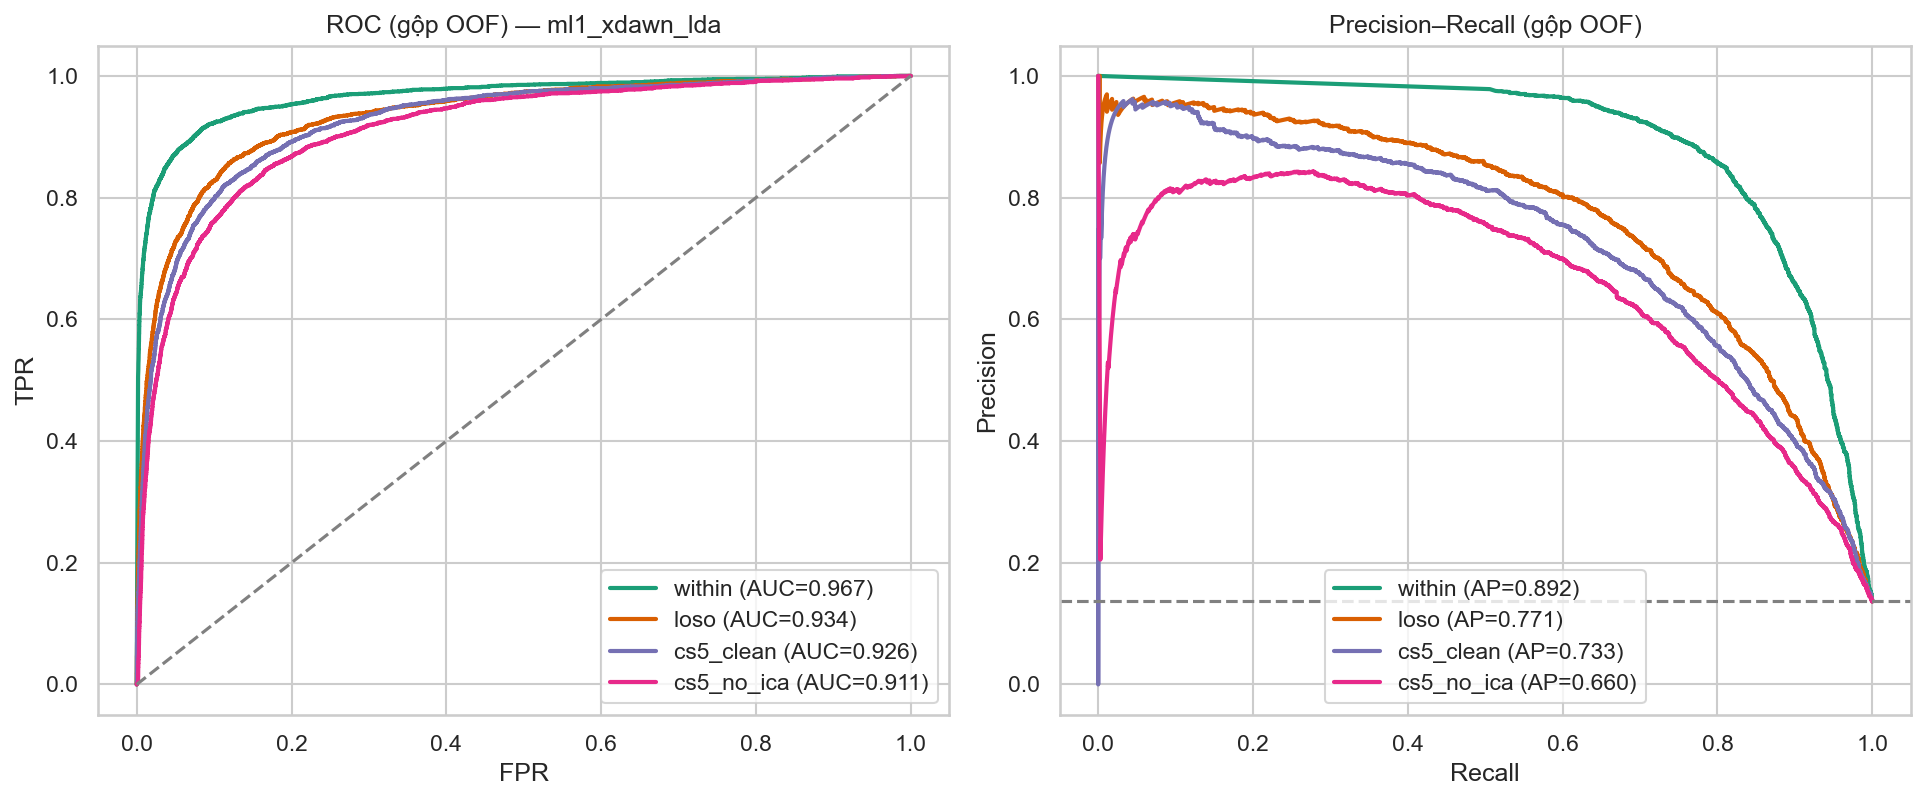

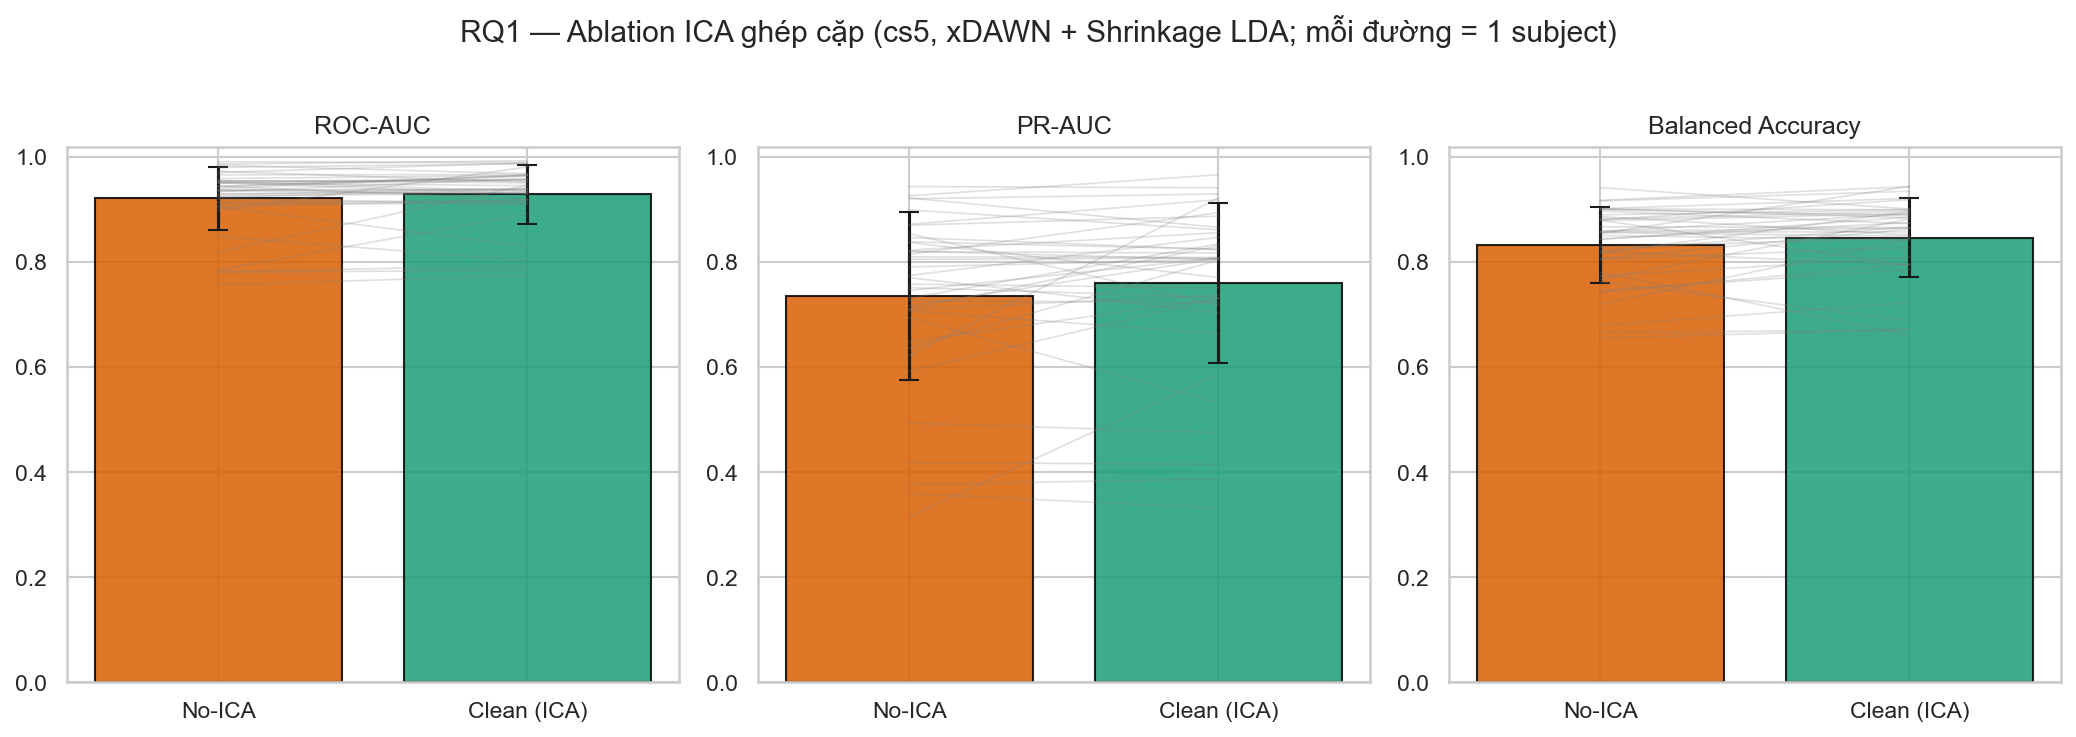

In [ ]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), dpi=150)
pal = {"within": "#1b9e77", "loso": "#d95f02", "cs5_clean": "#7570b3", "cs5_no_ica": "#e7298a"}
for setting in ["within", "loso", "cs5_clean", "cs5_no_ica"]:
    pr = RESULTS[(MODEL_MAIN, setting)][1]
    fpr, tpr, _ = roc_curve(pr["y_true"], pr["y_prob"]); pre, rec, _ = precision_recall_curve(pr["y_true"], pr["y_prob"])
    axes[0].plot(fpr, tpr, color=pal[setting], lw=2, label=f"{setting} (AUC={roc_auc_score(pr['y_true'], pr['y_prob']):.3f})")
    axes[1].plot(rec, pre, color=pal[setting], lw=2, label=f"{setting} (AP={average_precision_score(pr['y_true'], pr['y_prob']):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray"); axes[0].set(xlabel="FPR", ylabel="TPR", title=f"ROC (gộp OOF) — {MODEL_MAIN}")
axes[1].axhline(n1 / (n0 + n1), ls="--", color="gray"); axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–Recall (gộp OOF)")
for a in axes: a.legend(loc="best")
fig.tight_layout(); fig.savefig(figures_dir / "ml1_roc_pr_curves.png", dpi=300); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), dpi=150)
for ax, m, t in zip(axes, ["roc_auc", "pr_auc", "bal_acc"], ["ROC-AUC", "PR-AUC", "Balanced Accuracy"]):
    vals = [sn[m], sc[m]]
    ax.bar([0, 1], [v.mean() for v in vals], yerr=[v.std() for v in vals], capsize=5,
           color=["#d95f02", "#1b9e77"], edgecolor="black", alpha=0.85)
    for i in range(len(sc)):
        ax.plot([0, 1], [sn[m].iloc[i], sc[m].iloc[i]], color="gray", alpha=0.25, lw=0.8)   # đường nối ghép cặp từng subject
    ax.set_xticks([0, 1]); ax.set_xticklabels(["No-ICA", "Clean (ICA)"]); ax.set_title(t); ax.set_ylim(0, 1.02)
fig.suptitle("RQ1 — Ablation ICA ghép cặp (cs5, xDAWN + Shrinkage LDA; mỗi đường = 1 subject)", y=1.02)
fig.tight_layout(); fig.savefig(figures_dir / "ml1_ablation_ica.png", dpi=300, bbox_inches="tight"); plt.show()

In [ ]:
# --- Kiểm tra cuối: toàn bộ file bàn giao ---
print("FILE BÀN GIAO trong", handover_dir)
for (model, setting) in sorted(RESULTS):
    validate_handover(model, setting)
    print(f"  ✅ {model}_{setting}_per_fold.csv + _preds.npz")
print("\nFile thời gian/latency:", metrics_dir / "ml1_train_time.csv", "|", metrics_dir / "ml1_inference_latency.csv")
print("Chạy tiếp: pytest -v smoke_test/smoke_test_results.py")

FILE BÀN GIAO trong C:\visualstudiocode\MiniProject-TTKHTK\EEG-mini-project\results\handover_standard
  ✅ ml1_baseline_lr_cs5_clean_per_fold.csv + _preds.npz
  ✅ ml1_baseline_lr_cs5_no_ica_per_fold.csv + _preds.npz
  ✅ ml1_baseline_lr_within_per_fold.csv + _preds.npz
  ✅ ml1_xdawn_lda_cs5_clean_per_fold.csv + _preds.npz
  ✅ ml1_xdawn_lda_cs5_no_ica_per_fold.csv + _preds.npz
  ✅ ml1_xdawn_lda_loso_per_fold.csv + _preds.npz
  ✅ ml1_xdawn_lda_within_per_fold.csv + _preds.npz

File thời gian/latency: C:\visualstudiocode\MiniProject-TTKHTK\EEG-mini-project\results\metrics\ml1_train_time.csv | C:\visualstudiocode\MiniProject-TTKHTK\EEG-mini-project\results\metrics\ml1_inference_latency.csv
Chạy tiếp: pytest -v smoke_test/smoke_test_results.py


## Ghi chú phương pháp & hạn chế
- **xDAWN tự cài (`MemoryEfficientXdawn`)** cho bộ lọc trùng `mne.decoding.XdawnTransformer` (đã đối chiếu |cos| = 1), nhưng chịu được dữ liệu thiếu hạng (average reference + nội suy kênh — nguyên nhân `LinAlgError`) và dùng RAM thấp trên ~16–21k epoch.
- **Xử lý mất cân bằng 6.33 : 1:** `priors=[0.5, 0.5]` (LDA), `class_weight='balanced'` (LR), đánh giá bằng `bal_acc`, `pr_auc`, `f1_target`, `sensitivity`, `specificity`; **không dùng Accuracy** vì đoán toàn Frequent đã đạt ~86.4%.
- **Ablation** chỉ cô lập tác động của ICA trên cùng tập trial (`kept_in_clean == True`).
- `within` dùng chỉ số fold của nhóm (`StratifiedKFold`, có xáo trộn) nên có thể hơi lạc quan do tự tương quan theo thời gian; **LOSO là kết quả chính** cho khả năng tổng quát hóa.